# 쇼핑몰 단골 찾기 — 한 단계씩 실행하며 배우기

가상의 쇼핑몰에서 고객 240명이 약 9개월 동안 남긴 구매 기록으로 "누가 **최근에** 왔고, **자주** 오고, **많이** 쓰는지"를 계산한다. 이 세 숫자로 고객을 그룹으로 나누는 방법을 **RFM 분석**이라고 한다.

RFM을 계산하기 전에 데이터를 분석할 수 있는 상태로 만든다.

1. 거래 표와 상품 표를 연결한다.
2. 비어 있는 값(결측치)을 채운다.
3. 상품 이미지(숫자 배열)와 상품명(글자)을 숫자 특징으로 바꾼다.
4. 튀는 값(이상치)을 찾는다.

마지막 장에서는 지금까지 직접 계산한 단계를 `DataAnalyzer` 클래스 하나로 묶고, 같은 결과가 나오는지 확인한다.

**사용법:** 위에서부터 한 셀씩 실행한다. 코드를 한 줄씩 다 이해하지 못해도 괜찮다. 각 셀 아래의 **출력 읽기**가 출력에서 무엇을 보면 되는지 알려준다. **확인 질문**은 먼저 자기 말로 답해 본 뒤 접힌 답을 연다.

**구성:** 1~9장이 본편이다. 부록(A~C)은 보너스 과제(이미지 고급 피처, 코호트, 인터랙티브 차트)다. 데이터는 연습용으로 만든 합성 데이터라서, 결과를 실제 쇼핑몰에 대한 결론으로 읽지 않는다.

## 0. 준비

도구를 불러오고 데이터 폴더를 찾는다. 이 미션에서 쓰는 도구는 네 가지다.

- **NumPy**(`np`): 숫자 배열 계산. 이미지처럼 여러 축을 가진 숫자 덩어리를 다룬다.
- **Pandas**(`pd`): 행과 열이 있는 표 계산. 엑셀 시트를 코드로 다룬다고 생각하면 된다.
- **Matplotlib**(`plt`)·**Seaborn**(`sns`): 그래프 그리기.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

project_root = None
for candidate_folder in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate_folder / "src" / "pipeline.py").is_file() and (candidate_folder / "data" / "sample").is_dir():
        project_root = candidate_folder
        break

if project_root is None:
    raise FileNotFoundError("A1-1 폴더를 찾지 못했습니다. A1-1 또는 notebooks에서 실행하세요.")

DATA = project_root / "data" / "sample"
pd.set_option("display.float_format", "{:,.2f}".format)   # 1234567.0 → 1,234,567.00
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="colorblind")
print("프로젝트:", project_root.name)
print("데이터 파일:", sorted(path.name for path in DATA.iterdir()))

프로젝트: A1-1
데이터 파일: ['customers.csv', 'images.npy', 'metadata.json', 'products.csv', 'transactions.csv']


## 1. 데이터 세 개 — 거래·상품·이미지

이 미션의 데이터는 서로 다른 형태 세 가지다.

| 파일 | 내용 | 형태 |
| --- | --- | --- |
| `transactions.csv` | 누가 언제 무엇을 얼마에 샀나 | 표 |
| `products.csv` | 상품 이름·카테고리·가격·평점 | 표 |
| `images.npy` | 상품 사진 80장 | 숫자 배열 |

숫자·글자·날짜·이미지처럼 형태가 다른 데이터를 함께 다루는 것을 **멀티 모달** 데이터라고 한다.

ID 열(`line_id`, `order_id` 등)은 계산할 숫자가 아니라 이름표이므로 글자(`"string"`)로 읽는다.

In [2]:
transactions = pd.read_csv(DATA / "transactions.csv", dtype={
    "line_id": "string", "order_id": "string", "customer_id": "string", "product_id": "string"})
products = pd.read_csv(DATA / "products.csv", dtype={"product_id": "string"})
images = np.load(DATA / "images.npy")

print("거래 표 (행, 열):", transactions.shape)
print("상품 표 (행, 열):", products.shape)
print("이미지 배열 모양:", images.shape)
display(transactions.head())

거래 표 (행, 열): (2842, 11)
상품 표 (행, 열): (80, 6)
이미지 배열 모양: (80, 16, 16, 3)


,line_id,order_id,customer_id,order_date,product_id,unit_price,quantity,amount,country,payment_method,shipping_days
0,L00000,O00000,C000,2026-04-26,P063,"69,600.00",4,"278,400.00",KR,Card,4.00
1,L00001,O00000,C000,2026-04-26,P071,"24,900.00",3,"74,700.00",KR,Transfer,4.00
2,L00002,O00000,C000,2026-04-26,P078,"71,400.00",1,"71,400.00",KR,Wallet,2.00
3,L00003,O00001,C000,2026-06-01,P074,"53,400.00",4,"213,600.00",US,Card,1.00
4,L00004,O00001,C000,2026-06-01,P065,"78,900.00",3,"236,700.00",KR,Wallet,6.00


**출력 읽기:** `shape`은 (행 수, 열 수)다. 거래 표의 첫 세 행은 모두 `order_id`가 `O00000`이다. 거래 표의 **한 행은 주문 하나가 아니라 주문 안의 상품 한 줄**이다. 장바구니에 상품 세 개를 담아 한 번 결제하면 세 행이 생긴다.

그래서 "행 수", "주문 수", "고객 수"는 모두 다른 숫자다. `nunique()`는 서로 다른 값의 개수를 센다.

In [3]:
print("거래 행 수:", len(transactions))
print("주문 수:", transactions["order_id"].nunique())
print("고객 수:", transactions["customer_id"].nunique())
print("상품 수:", products["product_id"].nunique())

거래 행 수: 2842
주문 수: 1389
고객 수: 240
상품 수: 80


**확인 질문:** 고객 한 명이 몇 번 샀는지(구매 횟수)를 셀 때, 그 고객의 거래 행 수를 세면 왜 틀릴까?
<details><summary>답 확인</summary>상품 세 개를 한 번에 산 주문은 세 행이다. 행을 세면 한 번 산 것을 세 번 산 것으로 센다. 구매 횟수는 서로 다른 <code>order_id</code>의 수로 세야 한다. 7장에서 실제로 행 수로 세어 결과가 어떻게 틀어지는지 확인한다.</details>

### 열마다 무슨 뜻일까

두 표의 열 뜻을 정리한다. 최솟값·최댓값은 실제 데이터에서 계산한다. 글자 열은 비워 둔다.

In [4]:
column_meanings = {
    "line_id": "거래 줄 ID. 행마다 하나",
    "order_id": "주문 ID. 한 주문에 상품 여러 줄이 있을 수 있다",
    "customer_id": "고객 ID",
    "order_date": "주문 날짜",
    "product_id": "상품 ID. 상품 표와 연결하는 열쇠",
    "unit_price": "판매 단가(원). 상품 1개 가격",
    "quantity": "수량(개)",
    "amount": "결제 금액(원) = 단가 × 수량",
    "country": "주문 국가 (KR, JP, US)",
    "payment_method": "결제 수단 (Card, Transfer, Wallet)",
    "shipping_days": "배송에 걸린 일수(일). 일부 비어 있음",
    "product_name": "상품명. 일부 비어 있음",
    "category": "카테고리 (Home, Fashion, Beauty, Electronics)",
    "catalog_price": "상품 표에 적힌 정가(원). 일부 비어 있음",
    "rating": "상품 평점(점). 일부 비어 있음",
    "image_index": "이미지 배열에서 이 상품 사진의 위치 번호",
}

column_guide = pd.DataFrame({"뜻": column_meanings})
column_guide["표"] = ["거래"] * 11 + ["상품"] * 5
for column in column_guide.index:
    table = transactions if column in transactions.columns else products
    if pd.api.types.is_numeric_dtype(table[column]):
        column_guide.loc[column, "최솟값"] = table[column].min()
        column_guide.loc[column, "최댓값"] = table[column].max()
display(column_guide.fillna(""))

,뜻,표,최솟값,최댓값
line_id,거래 줄 ID. 행마다 하나,거래,,
order_id,주문 ID. 한 주문에 상품 여러 줄이 있을 수 있다,거래,,
customer_id,고객 ID,거래,,
order_date,주문 날짜,거래,,
product_id,상품 ID. 상품 표와 연결하는 열쇠,거래,,
unit_price,판매 단가(원). 상품 1개 가격,거래,"5,100.00","81,900.00"
quantity,수량(개),거래,1.00,4.00
amount,결제 금액(원) = 단가 × 수량,거래,"5,100.00","327,600.00"
country,"주문 국가 (KR, JP, US)",거래,,
payment_method,"결제 수단 (Card, Transfer, Wallet)",거래,,


**출력 읽기:** 거래 표의 `unit_price`와 상품 표의 `catalog_price`는 둘 다 가격이지만 쓰임이 다르다. `unit_price`는 실제로 팔린 가격이라 매출과 RFM 계산에 쓰고, `catalog_price`는 상품의 속성이라 3장에서 빈 값을 채우는 연습에 쓴다. `image_index`는 0~79이므로 이미지 80장 중 하나를 가리킨다.

### 데이터 구조 파악 — `info()`와 `describe()`

- `head()`: 앞의 몇 행을 보여준다. 위에서 이미 봤다.
- `info()`: 열마다 자료형(Dtype)과 비어 있지 않은 값의 개수(Non-Null Count)를 보여준다.
- `describe()`: 숫자 열마다 개수·평균·표준편차·최솟값·사분위수·최댓값을 계산한다.

In [5]:
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 2842 entries, 0 to 2841
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   line_id         2842 non-null   string 
 1   order_id        2842 non-null   string 
 2   customer_id     2842 non-null   string 
 3   order_date      2842 non-null   str    
 4   product_id      2842 non-null   string 
 5   unit_price      2842 non-null   float64
 6   quantity        2842 non-null   int64  
 7   amount          2842 non-null   float64
 8   country         2842 non-null   str    
 9   payment_method  2842 non-null   str    
 10  shipping_days   2570 non-null   float64
dtypes: float64(3), int64(1), str(3), string(4)
memory usage: 244.4 KB


**출력 읽기:**

- 거래 행은 2,842개인데 `shipping_days`(배송 일수)만 Non-Null이 그보다 적다. 이 차이가 **결측치**(비어 있는 값)의 개수다(3장).
- `float64`는 소수, `int64`는 정수, `string`·`str`은 글자다. `order_date`도 글자로 읽혔다. 글자 상태로는 "며칠 지났나"를 계산할 수 없으므로 날짜로 바꾼다.

In [6]:
transactions["order_date"] = pd.to_datetime(transactions["order_date"])
print("자료형:", transactions["order_date"].dtype)
print("첫 거래일:", transactions["order_date"].min().date())
print("마지막 거래일:", transactions["order_date"].max().date())

자료형: datetime64[us]
첫 거래일: 2026-01-11
마지막 거래일: 2026-10-09


In [7]:
display(transactions.describe())

,order_date,unit_price,quantity,amount,shipping_days
count,2842,"2,842.00","2,842.00","2,842.00","2,570.00"
mean,2026-07-28 17:58:43.997185,"40,497.08",2.47,"100,352.64",4.87
min,2026-01-11 00:00:00,"5,100.00",1.00,"5,100.00",1.00
25%,2026-06-28 00:00:00,"21,100.00",1.00,"39,900.00",3.00
50%,2026-08-17 00:00:00,"37,800.00",2.00,"75,000.00",5.00
75%,2026-09-09 00:00:00,"54,000.00",3.00,"148,650.00",7.00
max,2026-10-09 00:00:00,"81,900.00",4.00,"327,600.00",60.00
std,NaN,"22,539.12",1.12,"76,630.08",4.79


**출력 읽기:** 행 이름은 pandas가 붙인 영어다. `count`는 개수, `mean`은 평균, `std`는 표준편차(흩어진 정도, 4장에서 직접 계산한다), `min`·`max`는 최솟값·최댓값이다. `25%`, `50%`, `75%`는 **사분위수**다. 값을 작은 순서로 줄 세웠을 때 25%, 50%, 75% 위치에 있는 값이다. `50%`는 가운데 값인 **중앙값**이다.

`shipping_days`를 보자. 75%가 7일 이하인데 최댓값은 60일이다. 대부분과 동떨어진 값이 섞여 있다는 신호다(5장).

미션은 이런 해석을 **수치 근거 1개 이상 + 시사점 1문장**으로 쓰라고 한다. 예를 들면 이렇다.

> 배송 일수는 75%가 7일 이하이지만 최댓값은 60일이다(근거). 극단값이 평균을 끌어올릴 수 있으므로 배송 일수를 요약할 때는 중앙값을 함께 본다(시사점).

### 이 데이터를 만든 규칙

이 데이터는 생성 코드(`src/sample_data.py`)로 만들었다. 고객 240명을 60명씩 네 유형으로 만들었다.

| 고객 번호 | 주문 수 | 마지막 구매 | 특징 |
| --- | --- | --- | --- |
| C000~C059 | 10~16회 | 0~14일 전 | 비싼 Electronics 상품만 산다 |
| C060~C119 | 4~8회 | 10~44일 전 | 꾸준히 산다 |
| C120~C179 | 1회 | 0~7일 전 | 막 첫 구매를 했다 |
| C180~C239 | 2~5회 | 100~249일 전 | 한동안 오지 않았다 |

상품은 80개이고 카테고리 네 개(Home, Fashion, Beauty, Electronics)에 20개씩 있다. Electronics는 가격을 세 배로 만들었다. 일부 상품의 가격·평점·이름, 일부 거래의 배송 일수를 일부러 비웠고, 배송 일수 15건은 60일로 바꿨다.

실제 데이터에서는 이런 규칙을 모른다. 여기서는 규칙을 알고 있으므로, 7장에서 RFM 그룹이 이 네 유형을 다시 찾아내는지 확인할 수 있다.

## 2. 두 표 연결하기 — `merge`

거래 표에는 `product_id`만 있다. 카테고리·평점·이미지 위치는 상품 표에 있다. 두 표를 `product_id`로 맞춰 붙이는 것을 **merge**(조인)라고 한다.

작은 예로 먼저 본다. 거래 4행, 상품 2개다.

In [8]:
mini_transactions = pd.DataFrame({
    "order_id": ["O1", "O1", "O2", "O3"],
    "product_id": ["P1", "P2", "P1", "P1"],
    "amount": [100, 300, 100, 200],
})
mini_products = pd.DataFrame({
    "product_id": ["P1", "P2"],
    "category": ["Home", "Beauty"],
})

mini_joined = mini_transactions.merge(mini_products, on="product_id", how="left")
display(mini_joined)
print("매출 합계 — 연결 전:", mini_transactions["amount"].sum(), " 연결 후:", mini_joined["amount"].sum())

,order_id,product_id,amount,category
0,O1,P1,100,Home
1,O1,P2,300,Beauty
2,O2,P1,100,Home
3,O3,P1,200,Home


매출 합계 — 연결 전: 700  연결 후: 700


**출력 읽기:** 거래 4행이 그대로 4행으로 남고, 각 행에 그 상품의 카테고리가 붙었다. P1은 세 번 팔렸으므로 "Home"이 세 행에 반복된다. 이런 관계를 **다대일**(many-to-one, 거래 여러 행 → 상품 한 행)이라고 한다.

- `on="product_id"`: 어느 열을 기준으로 맞출지.
- `how="left"`: 왼쪽 표(거래)의 행을 모두 유지한다.

상품 표에 같은 `product_id`가 실수로 두 번 들어 있으면 어떻게 될까?

In [9]:
broken_products = pd.DataFrame({
    "product_id": ["P1", "P1", "P2"],
    "category": ["Home", "Home", "Beauty"],
})
broken_joined = mini_transactions.merge(broken_products, on="product_id", how="left")
print("거래 행 수:", len(mini_transactions), "→ 연결 후:", len(broken_joined))
print("매출 합계:", mini_transactions["amount"].sum(), "→ 연결 후:", broken_joined["amount"].sum())

거래 행 수: 4 → 연결 후: 7
매출 합계: 700 → 연결 후: 1100


**출력 읽기:** P1을 산 거래가 두 번씩 복제되어 행 수와 매출이 부풀었다. 오류 메시지 없이 숫자만 틀려지므로 알아채기 어렵다.

`validate="many_to_one"`을 붙이면 상품 표의 키가 중복일 때 연결을 멈추고 오류를 낸다. 실제 데이터에는 이 옵션을 붙여 연결한다.

In [10]:
joined = transactions.merge(products, on="product_id", how="left", validate="many_to_one")

print("거래 표:", transactions.shape, "→ 연결 후:", joined.shape)
print("매출 합계 같음:", transactions["amount"].sum() == joined["amount"].sum())
print("상품 정보가 안 붙은 행:", joined["category"].isna().sum())
display(joined.head(3))

거래 표: (2842, 11) → 연결 후: (2842, 16)
매출 합계 같음: True
상품 정보가 안 붙은 행: 0


,line_id,order_id,customer_id,order_date,product_id,unit_price,quantity,amount,country,payment_method,shipping_days,product_name,category,catalog_price,rating,image_index
0,L00000,O00000,C000,2026-04-26,P063,"69,600.00",4,"278,400.00",KR,Card,4.00,Electronics sample item 063,Electronics,"69,600.00",3.20,63
1,L00001,O00000,C000,2026-04-26,P071,"24,900.00",3,"74,700.00",KR,Transfer,4.00,Electronics sample item 071,Electronics,"24,900.00",3.90,71
2,L00002,O00000,C000,2026-04-26,P078,"71,400.00",1,"71,400.00",KR,Wallet,2.00,NaN,Electronics,"71,400.00",2.80,78


**출력 읽기:** 행 수는 2,842로 같고, 열은 상품 표의 5개(`product_id` 제외)가 늘어 16개가 되었다. 카테고리가 비어 있는 행이 0개이므로 모든 거래가 상품 표의 상품을 가리킨다. 이후 분석은 이 `joined` 표로 한다.

## 3. 결측치 — 비어 있는 값을 그룹 통계로 채우기

`isna()`는 칸마다 비었는지(True/False)를 표시하고, `sum()`은 True의 개수를 센다. 상품 표와 연결된 거래 표에서 각각 세 본다.

In [11]:
missing_counts = pd.DataFrame({
    "products (상품 80개)": products.isna().sum(),
    "joined (거래 2,842행)": joined.isna().sum(),
}).fillna(0).astype(int)
display(missing_counts[missing_counts.sum(axis=1) > 0])

,products (상품 80개),"joined (거래 2,842행)"
catalog_price,12,431
product_name,5,314
rating,7,285
shipping_days,0,272


**출력 읽기:** 가격(`catalog_price`)이 빈 상품은 12개인데, 거래 표에서는 431행이 비어 있다. 가격이 빈 상품이 여러 번 팔려 빈칸도 함께 복제됐기 때문이다. 그래서 **상품의 속성은 상품 표에서 채운 뒤 거래 표에 다시 붙인다.** 배송 일수(`shipping_days`)는 거래마다 다른 값이므로 거래 표에서 채운다.

### 무엇으로 채울까 — 같은 카테고리의 중앙값

빈 가격을 전체 상품의 가격 하나로 채우면 Electronics(가격 세 배)와 Beauty를 같은 값으로 채우게 된다. 비슷한 상품끼리 묶어서, **같은 카테고리의 중앙값**으로 채운다. 평균 대신 중앙값을 쓰는 이유는 아주 비싼 상품 몇 개에 덜 끌려가기 때문이다.

`groupby("category")`는 표를 카테고리별 묶음으로 나눈다. 그 뒤에 `median()`을 붙이면 묶음마다 중앙값을 하나씩 계산한다.

In [12]:
category_median_price = products.groupby("category")["catalog_price"].median()
display(category_median_price)
print("전체 상품의 중앙값:", products["catalog_price"].median())

category
Beauty        17,250.00
Electronics   40,800.00
Fashion       17,750.00
Home          17,600.00
Name: catalog_price, dtype: float64

전체 상품의 중앙값: 20650.0


**출력 읽기:** Electronics의 중앙값은 다른 카테고리보다 두 배 이상 높다. 가격이 빈 상품 12개를 두 방법으로 채워 비교한다.

In [13]:
missing_price = products[products["catalog_price"].isna()]
fill_comparison = pd.DataFrame({
    "카테고리": missing_price["category"],
    "카테고리 중앙값으로": missing_price["category"].map(category_median_price),
    "전체 중앙값으로": products["catalog_price"].median(),
})
display(fill_comparison.groupby("카테고리").first())

,카테고리 중앙값으로,전체 중앙값으로
카테고리,,
Beauty,"17,250.00","20,650.00"
Electronics,"40,800.00","20,650.00"
Fashion,"17,750.00","20,650.00"
Home,"17,600.00","20,650.00"


**출력 읽기:** 전체 중앙값으로 채우면 Electronics 상품 3개가 카테고리 중앙값의 절반 정도 가격을 받고, Home·Fashion·Beauty 상품은 더 비싸게 잡힌다. 카테고리 중앙값은 비슷한 상품끼리의 기준이라 이런 쏠림이 작다.

카테고리별 중앙값은 카테고리당 한 값(4개)이다. 상품 80개의 각 행에 "내 카테고리의 중앙값"을 붙이려면 `transform`을 쓴다. 작은 예로 본다.

In [14]:
mini = pd.DataFrame({
    "category": ["A", "A", "A", "B", "B"],
    "price": [10, 40, np.nan, 100, np.nan],
})
mini["그룹 중앙값"] = mini.groupby("category")["price"].transform("median")
mini["채운 가격"] = mini["price"].fillna(mini["그룹 중앙값"])
display(mini)

,category,price,그룹 중앙값,채운 가격
0,A,10.00,25.00,10.00
1,A,40.00,25.00,40.00
2,A,NaN,25.00,25.00
3,B,100.00,100.00,100.00
4,B,NaN,100.00,100.00


**출력 읽기:** A 묶음의 값은 10과 40이므로 중앙값은 25다. 비어 있는 값(NaN)은 계산에서 빠진다. `transform`은 묶음의 결과를 **원래 행 개수 그대로** 돌려주므로 A의 세 행 모두에 25가 붙는다. `fillna`는 빈 칸에만 그 값을 넣고, 이미 값이 있는 칸은 그대로 둔다.

이제 실제 상품 표에 적용한다. 원본을 보존하기 위해 `copy()`로 사본을 만들어 채운다. 이름이 빈 상품은 `"Unknown product"`로 채운다.

In [15]:
products_filled = products.copy()
for column in ["catalog_price", "rating"]:
    group_median = products_filled.groupby("category")[column].transform("median")
    products_filled[column] = products_filled[column].fillna(group_median)
products_filled["product_name"] = products_filled["product_name"].fillna("Unknown product")

was_missing = products["catalog_price"].isna()
comparison = products.loc[was_missing, ["product_id", "category", "catalog_price"]].head(4)
comparison["채운 가격"] = products_filled.loc[was_missing, "catalog_price"].head(4)
display(comparison)
print("남은 결측치:", products_filled[["catalog_price", "rating", "product_name"]].isna().sum().to_dict())

,product_id,category,catalog_price,채운 가격
5,P005,Home,NaN,"17,600.00"
13,P013,Home,NaN,"17,600.00"
19,P019,Home,NaN,"17,600.00"
24,P024,Fashion,NaN,"17,750.00"


남은 결측치: {'catalog_price': 0, 'rating': 0, 'product_name': 0}


**출력 읽기:** 가격이 비어 있던 Home 상품에는 Home의 중앙값이, Electronics 상품에는 Electronics의 중앙값이 들어갔다. 위에서 계산한 카테고리별 중앙값과 같은 숫자다.

**왜 거래 표가 아니라 상품 표에서 채울까?** 10원 상품과 40원 상품이 하나씩 있고, 10원 상품만 세 번 팔렸다고 하자. 상품 표의 중앙값은 (10, 40)의 가운데인 25원이다. 거래 표 [10, 10, 10, 40]의 중앙값은 10원이다. 거래 표에서 계산하면 많이 팔린 상품의 가격이 더 큰 비중을 가진다. 실제 데이터로 두 중앙값을 비교한다.

In [16]:
display(pd.DataFrame({
    "상품 표에서 (상품마다 한 번)": products.groupby("category")["catalog_price"].median(),
    "거래 표에서 (팔린 횟수만큼)": joined.groupby("category")["catalog_price"].median(),
}))

,상품 표에서 (상품마다 한 번),거래 표에서 (팔린 횟수만큼)
category,,
Beauty,"17,250.00","17,000.00"
Electronics,"40,800.00","40,800.00"
Fashion,"17,750.00","20,300.00"
Home,"17,600.00","17,600.00"


**출력 읽기:** Fashion은 17,750원과 20,300원으로 차이가 크고, Beauty도 조금 다르다. 거래 표의 중앙값은 "어떤 상품이 많이 팔렸나"에 따라 움직인다. 상품의 속성은 상품 하나당 한 번씩 세는 것이 맞다.

채운 상품 속성을 거래 표에 다시 붙인다. `set_index("product_id")`로 상품 ID를 찾아보기 기준으로 만들고, `map`으로 거래마다 그 상품의 값을 찾아온다.

In [17]:
product_lookup = products_filled.set_index("product_id")
for column in ["catalog_price", "rating", "product_name"]:
    joined[column] = joined["product_id"].map(product_lookup[column])

# 배송 일수는 거래마다 다른 값이므로 거래 표에서 같은 카테고리의 중앙값으로 채운다.
shipping_median = joined.groupby("category")["shipping_days"].transform("median")
joined["shipping_days"] = joined["shipping_days"].fillna(shipping_median)

print("거래 표의 남은 결측치:", int(joined.isna().sum().sum()))

거래 표의 남은 결측치: 0


**확인 질문:** 결제 금액(`amount`)이 비어 있는 거래가 있다면, 이것도 카테고리 중앙값으로 채워도 될까?
<details><summary>답 확인</summary>채우면 안 된다. 가격·평점은 상품의 속성이라 비슷한 상품으로 짐작할 수 있지만, 결제 금액은 "실제로 얼마를 냈는가"라는 사실이다. 채우면 일어나지 않은 매출이 생겨 7장의 RFM이 틀어진다. 이런 행은 분석에서 빼고 몇 개를 뺐는지 기록한다. 이 데이터에는 금액 결측이 없다.</details>

## 4. 이미지와 글자를 숫자로 — 피처 만들기

분석에 쓰는 특징 값을 **피처**(feature)라고 한다. 이미지와 상품명은 그대로는 표의 한 칸에 넣어 비교하기 어렵다. 그래서 각각을 숫자 몇 개로 요약한다.

### 이미지 배열의 모양

이미지 배열의 모양 `(80, 16, 16, 3)`은 축 네 개를 뜻한다.

| 축 번호 | 크기 | 뜻 |
| --- | --- | --- |
| 0 | 80 | 이미지(상품) 번호 |
| 1 | 16 | 세로 위치(픽셀 행) |
| 2 | 16 | 가로 위치(픽셀 열) |
| 3 | 3 | 색 채널(빨강·초록·파랑, RGB) |

각 칸의 값은 0(어두움)~255(밝음)의 밝기다.

In [18]:
print("모양:", images.shape, " 자료형:", images.dtype)
print("최솟값:", images.min(), " 최댓값:", images.max())
print("0번 이미지, 맨 왼쪽 위 픽셀의 [R, G, B]:", images[0, 0, 0])

모양: (80, 16, 16, 3)  자료형: uint8
최솟값: 0  최댓값: 255
0번 이미지, 맨 왼쪽 위 픽셀의 [R, G, B]: [59  0 48]


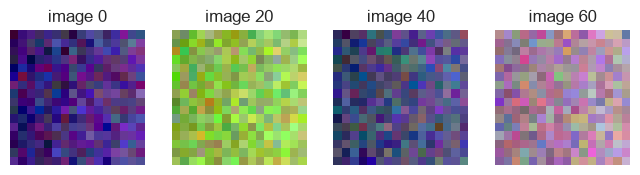

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for position, image_number in enumerate([0, 20, 40, 60]):
    axes[position].imshow(images[image_number])
    axes[position].set_title(f"image {image_number}")
    axes[position].axis("off")
plt.show()

**출력 읽기:** 16×16 픽셀짜리 작은 합성 이미지다. 실제 상품 사진이 아니라 밝기와 거친 정도가 서로 다르게 만든 연습용 배열이다.

### 이미지 한 장 → 평균과 표준편차

이미지 한 장에는 16 × 16 × 3 = 768개의 숫자가 있다. 이것을 두 숫자로 요약한다.

- **평균**: 전체적으로 얼마나 밝은가.
- **표준편차**: 값이 평균에서 보통 얼마나 떨어져 있는가. 무늬가 많고 거칠수록 커진다.

표준편차는 네 단계로 계산한다. [0, 0, 100, 100]으로 따라간다.

1. 값마다 평균과의 차이를 구한다.
2. 차이를 제곱한다. −50과 +50을 그냥 더하면 0이 되어 흩어짐이 사라지므로, 제곱해서 모두 양수로 만든다.
3. 제곱한 값의 평균을 낸다(**분산**).
4. 제곱근을 씌운다. 제곱하면서 단위도 제곱(밝기²)이 되었으므로 원래 단위로 되돌린다.

In [20]:
values = np.array([0, 0, 100, 100])
differences = values - values.mean()
squared = differences ** 2
variance = squared.mean()
print("평균:", values.mean())
print("1 평균과의 차이:", differences)
print("2 제곱:", squared)
print("3 제곱의 평균(분산):", variance)
print("4 제곱근(표준편차):", np.sqrt(variance), " np.std:", values.std())
print("[50, 50, 50, 50]의 표준편차:", np.std([50, 50, 50, 50]))

평균: 50.0
1 평균과의 차이: [-50. -50.  50.  50.]
2 제곱: [2500. 2500. 2500. 2500.]
3 제곱의 평균(분산): 2500.0
4 제곱근(표준편차): 50.0  np.std: 50.0
[50, 50, 50, 50]의 표준편차: 0.0


**출력 읽기:** 두 배열은 평균이 50으로 같지만 표준편차는 50과 0이다. 모든 값이 평균에서 50씩 떨어진 배열과 하나도 떨어지지 않은 배열이다. 이제 이미지 한 장에 적용한다.

In [21]:
first_image = images[0]
print("0번 이미지의 숫자 개수:", first_image.size)
print("0번 이미지 평균:", first_image.mean())
print("0번 이미지 표준편차:", first_image.std())

0번 이미지의 숫자 개수: 768
0번 이미지 평균: 79.43229166666667
0번 이미지 표준편차: 44.821469917681156


### 80장을 한 번에 — `axis`와 벡터 연산

반복문으로 80장을 하나씩 계산할 수도 있다. 하지만 미션은 **반복문 대신 배열 연산**(벡터 연산)을 쓰라고 한다. NumPy는 `axis`로 "어느 축을 따라 계산할지"를 지정하면 배열 전체를 한 번에 계산한다. 반복문보다 짧고 훨씬 빠르다.

`axis`를 2×3 배열로 먼저 본다. **`axis`에 적은 축이 계산되어 사라진다.**

In [22]:
small = np.array([[1, 2, 3],
                  [4, 5, 6]])
print("모양:", small.shape)
print("axis=0 (세로로 계산, 열마다 하나):", small.mean(axis=0))
print("axis=1 (가로로 계산, 행마다 하나):", small.mean(axis=1))

모양: (2, 3)
axis=0 (세로로 계산, 열마다 하나): [2.5 3.5 4.5]
axis=1 (가로로 계산, 행마다 하나): [2. 5.]


**출력 읽기:** `axis=0`이면 0번 축(행 2개)이 사라져 열마다 하나씩, 숫자 3개가 남는다. `axis=1`이면 1번 축(열 3개)이 사라져 행마다 하나씩, 숫자 2개가 남는다.

이미지 배열에서는 0번 축(이미지 번호)만 남기고 1·2·3번 축(세로·가로·색)을 모두 계산해 없앤다. 그러면 이미지마다 평균이 하나씩 남는다. 반복문 결과와 비교한다.

In [23]:
# 이해를 돕기 위한 반복문 버전: 한 장씩 꺼내 평균을 구한다.
image_mean_by_loop = []
for image_number in range(len(images)):
    image_mean_by_loop.append(images[image_number].mean())

# 미션에서 쓰는 벡터 연산 버전: 1·2·3번 축을 한 번에 계산한다.
image_mean = images.mean(axis=(1, 2, 3))
image_std = images.std(axis=(1, 2, 3))

print("벡터 연산 결과 모양:", image_mean.shape)
print("반복문과 같은 값:", np.allclose(image_mean, image_mean_by_loop))
print("앞의 세 이미지 평균:", image_mean[:3])
print("앞의 세 이미지 표준편차:", image_std[:3])

벡터 연산 결과 모양: (80,)
반복문과 같은 값: True
앞의 세 이미지 평균: [ 79.43229167 142.61588542 120.328125  ]
앞의 세 이미지 표준편차: [44.82146992 45.21717972 57.39434714]


**출력 읽기:** `(80, 16, 16, 3)`이 `(80,)`이 되었다. 상품 80개마다 숫자 하나씩이다. 0번 값은 위에서 한 장만 계산한 값과 같다.

### 상품별 값 → 거래 행에 붙이기

통계는 상품 80개분이지만 거래 표는 2,842행이다. 거래 행마다 `image_index`(그 상품의 이미지 번호)가 있으므로, 배열에서 그 위치의 값을 꺼내 붙이면 된다. 배열에 위치 목록을 넣으면 그 위치들의 값을 순서대로 꺼낸다.

In [24]:
stats = np.array([20.0, 80.0])
positions = np.array([1, 0, 1])
print("stats[[1, 0, 1]] =", stats[positions])

positions_in_joined = joined["image_index"].to_numpy()
joined["image_mean"] = image_mean[positions_in_joined]
joined["image_std"] = image_std[positions_in_joined]
display(joined[["product_id", "image_index", "image_mean", "image_std"]].head())

stats[[1, 0, 1]] = [80. 20. 80.]


,product_id,image_index,image_mean,image_std
0,P063,63,105.79,39.89
1,P071,71,118.80,61.30
2,P078,78,120.57,46.83
3,P074,74,148.60,49.99
4,P065,65,138.71,34.38


**출력 읽기:** 작은 예에서 위치 [1, 0, 1]은 [80, 20, 80]이 되었다. 같은 상품이 여러 번 팔려도 거래 행마다 그 상품의 이미지 통계가 붙는다.

이 두 숫자는 밝기와 거친 정도의 요약일 뿐, 사진 속 물건이 무엇인지는 알려주지 않는다.

### 상품명 → 글자 수와 단어 수

`.str`은 글자 열 전체에 글자 기능을 적용한다. `str.len()`은 글자 수(공백 포함), `str.split()`은 공백으로 나눈 단어 목록이다.

In [25]:
joined["name_length"] = joined["product_name"].str.len()
joined["name_word_count"] = joined["product_name"].str.split().str.len()
display(joined[["product_name", "name_length", "name_word_count"]].drop_duplicates().head())

,product_name,name_length,name_word_count
0,Electronics sample item 063,27,4
1,Electronics sample item 071,27,4
2,Unknown product,15,2
3,Electronics sample item 074,27,4
4,Electronics sample item 065,27,4


**출력 읽기:** "Home sample item 001"은 공백 포함 20글자, 단어 4개다. 이름이 비어 "Unknown product"로 채운 상품은 단어 2개가 된다. 이름의 의미를 이해한 값이 아니라 길이만 센 값이다.

**확인 질문:** `images.mean(axis=(1, 2))`라고 쓰면 결과의 모양은 무엇이고, 무엇을 뜻할까?
<details><summary>답 확인</summary>1·2번 축(세로·가로)만 사라지고 0번(이미지)과 3번(색)이 남아 <code>(80, 3)</code>이 된다. 이미지마다 빨강·초록·파랑 채널의 평균 밝기를 따로 구한 것이다. 실행해서 확인해 본다.</details>

## 5. 이상치 — IQR로 튀는 값 찾기

다른 값들과 동떨어진 값을 **이상치**라고 한다. 이상치를 찾는 기준으로 **IQR**을 쓴다.

- **Q1**: 25% 위치 값, **Q3**: 75% 위치 값.
- **IQR** = Q3 − Q1. 가운데 50% 값들이 퍼진 폭이다.
- **하한** = Q1 − 1.5 × IQR, **상한** = Q3 + 1.5 × IQR. 이 범위 밖이면 이상치 후보다.

[10, 20, 30, 40, 100]으로 계산해 본다.

In [26]:
example = pd.Series([10, 20, 30, 40, 100])
q1 = example.quantile(0.25)
q3 = example.quantile(0.75)
iqr = q3 - q1
print("Q1:", q1, " Q3:", q3, " IQR:", iqr)
print("하한:", q1 - 1.5 * iqr, " 상한:", q3 + 1.5 * iqr)

Q1: 20.0  Q3: 40.0  IQR: 20.0
하한: -10.0  상한: 70.0


**출력 읽기:** 범위는 −10~70이므로 100이 후보가 된다. 평균이나 표준편차를 쓰지 않고 사분위수를 쓰므로, 100 같은 극단값 자체가 기준을 끌어올리지 않는다.

미션은 이 로직을 **직접 함수로** 만들라고 한다. 1.5라는 배수를 `threshold` 인자로 받아 바꿀 수 있게 한다.

In [27]:
def iqr_bounds(values, threshold=1.5):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    return float(q1 - threshold * iqr), float(q3 + threshold * iqr)

shipping = joined["shipping_days"]
lower, upper = iqr_bounds(shipping)
is_outlier = (shipping < lower) | (shipping > upper)

print("배송 일수 하한:", lower, " 상한:", upper)
print("이상치 후보 수:", is_outlier.sum())
print("후보들의 값:", shipping[is_outlier].value_counts().to_dict())

배송 일수 하한: -1.5  상한: 10.5
이상치 후보 수: 15
후보들의 값: {60.0: 15}


**출력 읽기:**

- 상한은 10.5일이다. 하한은 음수(−1.5일)인데 배송 일수는 음수가 될 수 없으므로 아래쪽 후보는 없다.
- 후보 15건은 모두 60일이다. 데이터를 만들 때 넣은 15건을 정확히 찾았다.
- `|`는 "또는"이다. 각 행마다 "하한보다 작다 또는 상한보다 크다"를 계산해 True/False 열을 만든다.

### 찾기와 처리는 다르다

IQR은 "확인해 볼 후보"를 알려줄 뿐, 그 값이 잘못됐다고 판정하지 않는다. 60일 배송은 입력 실수일 수도, 실제 해외 배송 지연일 수도 있다. 처리 방법 두 가지를 비교한다.

- **clip(자르기)**: 경계 밖 값을 경계값으로 바꾼다. 60 → 10.5. 행 수는 그대로다.
- **remove(빼기)**: 경계 밖 행을 뺀다. 행 수가 줄어든다.

In [28]:
clipped = shipping.clip(lower, upper)
removed = shipping[shipping.between(lower, upper)]

display(pd.DataFrame({
    "행 수": [len(shipping), len(clipped), len(removed)],
    "평균": [shipping.mean(), clipped.mean(), removed.mean()],
    "중앙값": [shipping.median(), clipped.median(), removed.median()],
    "최댓값": [shipping.max(), clipped.max(), removed.max()],
}, index=["원본", "clip(자르기)", "remove(빼기)"]))

,행 수,평균,중앙값,최댓값
원본,2842,4.87,5.00,60.00
clip(자르기),2842,4.61,5.00,10.50
remove(빼기),2827,4.58,5.00,8.00


**출력 읽기:** 15건 때문에 평균이 눈에 띄게 올라가 있었다. 처리하면 평균은 내려가지만, 중앙값은 거의 그대로다. 중앙값이 극단값에 강하다는 것을 숫자로 확인할 수 있다.

미션은 처리 전후의 분포 변화를 시각화하라고 한다. **박스플롯**으로 비교한다.

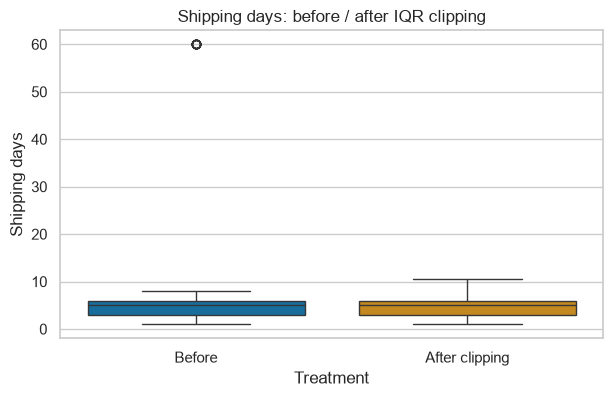

In [29]:
comparison = pd.DataFrame({"Before": shipping, "After clipping": clipped})
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=comparison, ax=ax)
ax.set(title="Shipping days: before / after IQR clipping", xlabel="Treatment", ylabel="Shipping days")
plt.show()

**출력 읽기:** 상자의 아래·위 끝은 Q1·Q3, 상자 안의 선은 중앙값이다. 상자 밖으로 뻗은 선(수염)은 IQR 경계 안의 가장 먼 값까지 닿는다. 그 밖의 점이 이상치 후보다. 처리 전에는 60일 점이 멀리 떨어져 있어 상자가 아래쪽에 납작하게 눌려 보인다. 처리 후에는 60일 점이 사라졌다.

같은 함수로 단가(`unit_price`)도 검사한다.

In [30]:
price_lower, price_upper = iqr_bounds(joined["unit_price"])
price_is_outlier = (joined["unit_price"] < price_lower) | (joined["unit_price"] > price_upper)
print("단가 상한:", price_upper, " 최댓값:", joined["unit_price"].max())
print("단가 이상치 후보 수:", price_is_outlier.sum())

# 9장에서 클래스 결과와 비교하기 위해 표시만 남긴다. 값은 바꾸지 않는다.
joined["shipping_days_is_outlier"] = is_outlier

단가 상한: 103350.0  최댓값: 81900.0
단가 이상치 후보 수: 0


**출력 읽기:** Electronics는 세 배 비싸지만 단가 후보는 0건이다. VIP 고객이 Electronics만 사기 때문에 거래 행의 약 2/3가 Electronics다. 비싼 거래가 흔하니 Q3 자체가 높다. 비싼 상품은 정상적인 판매이므로, 후보가 나왔더라도 지우면 VIP 고객의 매출이 사라진다.

이 노트북은 이상치를 **표시만** 하고 원래 값은 바꾸지 않는다. RFM의 금액은 실제 결제 금액을 그대로 쓴다.

**확인 질문:** `threshold`를 1.5에서 3.0으로 바꾸면 배송 일수의 후보는 늘까, 줄까?
<details><summary>답 확인</summary>경계가 IQR × 3만큼 넓어지므로 후보는 줄거나 같다. 이 데이터에서는 Q1 = 3, Q3 = 6, IQR = 3이므로 상한이 6 + 3 × 3 = 15일이 되어 60일 15건은 여전히 후보다. <code>iqr_bounds(shipping, threshold=3.0)</code>으로 확인해 본다.</details>

## 6. 요약 통계와 상관관계

### 평균·중앙값·표준편차·사분위수

- **평균**: 모두 더해 개수로 나눈 값. 극단값에 끌려간다.
- **중앙값**: 줄 세웠을 때 가운데 값. 극단값에 덜 흔들린다.
- **표준편차**: 평균 주변으로 얼마나 퍼져 있나.
- **사분위수**(25%·50%·75%): 분포의 아래·가운데·위 위치.

`describe()`의 결과를 `.T`로 뒤집으면(행과 열 교환) 변수 하나가 한 행이 되어 읽기 편하다. 열 이름은 한국어로 바꿔 표시한다.

In [31]:
numeric_columns = ["unit_price", "quantity", "amount", "shipping_days", "image_mean", "image_std"]
korean_stat_names = {"count": "개수", "mean": "평균", "std": "표준편차", "min": "최솟값",
                     "25%": "Q1(25%)", "50%": "중앙값(50%)", "75%": "Q3(75%)", "max": "최댓값"}
display(joined[numeric_columns].describe().T.rename(columns=korean_stat_names))

,개수,평균,표준편차,최솟값,Q1(25%),중앙값(50%),Q3(75%),최댓값
unit_price,"2,842.00","40,497.08","22,539.12","5,100.00","21,100.00","37,800.00","54,000.00","81,900.00"
quantity,"2,842.00",2.47,1.12,1.00,1.00,2.00,3.00,4.00
amount,"2,842.00","100,352.64","76,630.08","5,100.00","39,900.00","75,000.00","148,650.00","327,600.00"
shipping_days,"2,842.00",4.87,4.56,1.00,3.00,5.00,6.00,60.00
image_mean,"2,842.00",120.95,23.97,48.99,104.88,124.29,139.04,184.24
image_std,"2,842.00",46.46,10.84,28.28,37.67,46.83,52.63,70.90


**출력 읽기:** 금액(`amount`)은 평균(약 10만 원)이 중앙값(7만 5천 원)보다 크다. 큰 주문 일부가 평균을 위로 끌어올린 것이다. 이럴 때 "보통 주문 한 줄의 금액"을 말하려면 중앙값이 더 대표적이다. 단가는 평균과 중앙값이 비슷하다.

이 통계는 거래 행 기준이다. 많이 팔린 상품의 가격은 여러 번 들어간다. 상품 80개를 하나씩 센 가격 분포와는 다르다.

분포를 눈으로 보려면 **히스토그램**을 그린다. 값의 구간마다 행이 몇 개인지 막대로 센다.

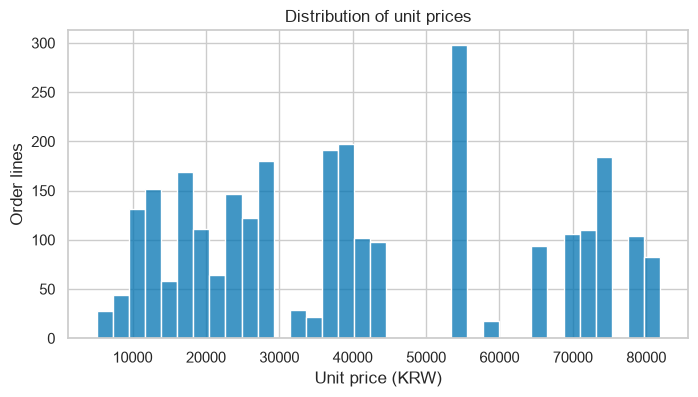

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=joined, x="unit_price", bins=35, ax=ax)
ax.set(title="Distribution of unit prices", xlabel="Unit price (KRW)", ylabel="Order lines")
plt.show()

**출력 읽기:** 단가는 하나의 봉우리가 아니라 여러 묶음으로 나뉘어 있다. 4만 5천 원 이상인 거래는 거의 모두 Electronics다. 상품이 80개뿐이라 같은 가격이 여러 번 팔려 막대가 듬성듬성하다. 평균과 중앙값이 비슷해도 분포 모양은 이렇게 울퉁불퉁할 수 있으므로, 숫자 요약과 그림을 함께 본다.

### 상관계수 — 두 변수가 함께 움직이는 정도

**상관계수**(Pearson r)는 −1~1 사이 값이다. 1에 가까우면 한쪽이 클 때 다른 쪽도 크고, −1에 가까우면 반대로 움직이며, 0에 가까우면 직선 관계가 거의 없다.

계산은 세 단계다.

1. 두 변수를 각각 **표준화**한다: (값 − 평균) ÷ 표준편차. 단위가 사라지고 "평균보다 표준편차 몇 개만큼 큰가"만 남는다. 단가(원)와 수량(개)처럼 단위가 다른 변수를 비교하려면 이 단계가 필요하다.
2. 같은 행끼리 곱한다. 둘 다 평균보다 크거나 둘 다 작으면 곱이 양수, 한쪽만 크면 음수다.
3. 곱의 평균을 낸다. 같은 방향으로 움직인 행이 많을수록 양수로 커진다.

x = [1, 2, 3, 4], y = [2, 4, 5, 8]로 따라간다.

In [33]:
x = pd.Series([1, 2, 3, 4])
y = pd.Series([2, 4, 5, 8])
x_standardized = (x - x.mean()) / x.std(ddof=0)
y_standardized = (y - y.mean()) / y.std(ddof=0)
products_of_pairs = x_standardized * y_standardized

display(pd.DataFrame({"x 표준화": x_standardized, "y 표준화": y_standardized, "곱": products_of_pairs}))
print("곱의 평균(직접 계산):", products_of_pairs.mean(), " corr():", x.corr(y))

,x 표준화,y 표준화,곱
0,-1.34,-1.27,1.70
1,-0.45,-0.35,0.15
2,0.45,0.12,0.05
3,1.34,1.50,2.01


곱의 평균(직접 계산): 0.9811557810392122  corr(): 0.9811557810392122


**출력 읽기:** 처음 두 행은 둘 다 평균보다 작고, 뒤 두 행은 둘 다 평균보다 커서 곱이 모두 양수다. 그래서 r이 1에 가깝다. `ddof=0`은 표준편차를 n으로 나누라는 뜻이다. 4장의 `np.std`와 같은 방식이다.

미션은 최소 2쌍을 계산하고 해석하라고 한다.

In [34]:
pairs = [("unit_price", "amount"), ("quantity", "amount"),
         ("image_mean", "unit_price"), ("shipping_days", "amount")]
for left, right in pairs:
    r = joined[left].corr(joined[right])
    print(f"{left} – {right}: r = {r:.2f}")

unit_price – amount: r = 0.73
quantity – amount: r = 0.61
image_mean – unit_price: r = 0.16
shipping_days – amount: r = 0.04


**출력 읽기:**

- 단가–금액(0.73), 수량–금액(0.61)은 높다. 그러나 금액 = 단가 × 수량으로 **계산된 값**이므로 당연한 결과다. 새 발견이 아니다.
- 이미지 밝기–단가(0.16), 배송 일수–금액(0.04)은 0에 가깝다. 직선 관계가 거의 없다.
- 상관은 "함께 움직인다"는 뜻이지 "원인이다"는 뜻이 아니다. 밝은 사진이 가격을 올린다고 해석하면 안 된다.

여러 변수의 상관계수를 한 번에 보려면 **히트맵**을 그린다. 칸의 색이 상관계수의 크기다.

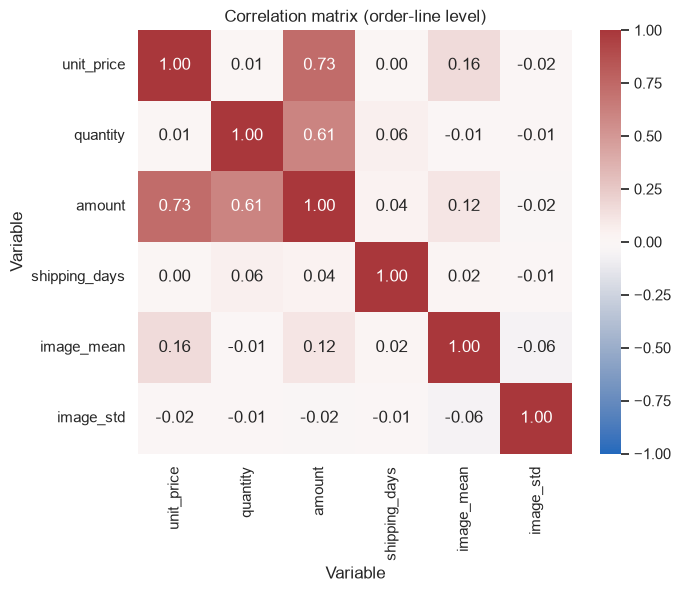

In [35]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(joined[numeric_columns].corr(), annot=True, fmt=".2f",
            vmin=-1, vmax=1, center=0, cmap="vlag", ax=ax)
ax.set(title="Correlation matrix (order-line level)", xlabel="Variable", ylabel="Variable")
plt.show()

**출력 읽기:** 대각선은 자기 자신과의 상관이라 항상 1이다. 진한 색은 금액과 그 재료(단가·수량) 사이에서만 나온다.

### 시간 추세 — 월별 매출

`dt.to_period("M")`은 날짜를 "2026-03" 같은 월로 바꾼다. 월로 묶어 금액을 더하면 월별 매출이다. 시간에 따른 변화는 **라인차트**로 그린다.

,매출(원)
order_date,
2026-01,"1,408,900.00"
2026-02,"6,518,600.00"
2026-03,"5,383,800.00"
2026-04,"10,027,400.00"
2026-05,"18,750,000.00"
2026-06,"28,656,800.00"
2026-07,"39,240,400.00"
2026-08,"76,649,000.00"
2026-09,"78,475,800.00"


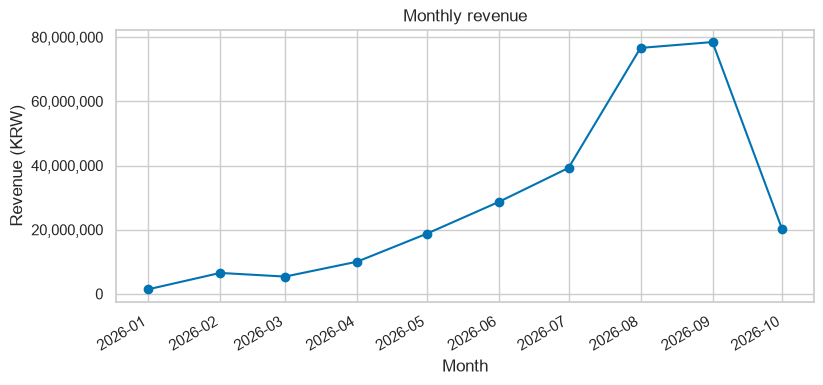

In [36]:
monthly_revenue = joined.groupby(joined["order_date"].dt.to_period("M"))["amount"].sum()
display(monthly_revenue.to_frame("매출(원)"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly_revenue.index.to_timestamp(), monthly_revenue.values, marker="o")
ax.set(title="Monthly revenue", xlabel="Month", ylabel="Revenue (KRW)")
ax.yaxis.set_major_formatter("{x:,.0f}")
fig.autofmt_xdate()
plt.show()

**출력 읽기:** 데이터는 1월 11일에 시작해 10월 9일에 끝난다. 첫 달과 마지막 달은 한 달을 다 채우지 못했다. 양 끝이 낮은 것을 "매출이 줄었다"로 읽으면 안 된다. 이 데이터는 마지막 구매일 기준으로 고객을 만들었기 때문에, 최근 달로 갈수록 활동 중인 고객이 많아 매출이 늘어 보인다.

## 7. RFM — 고객을 숫자 세 개로 요약하기

| 글자 | 뜻 | 계산 | 좋은 방향 |
| --- | --- | --- | --- |
| **R**ecency | 최근성 | 기준일 − 마지막 구매일(일) | 작을수록 |
| **F**requency | 빈도 | 서로 다른 주문 수 | 클수록 |
| **M**onetary | 금액 | 결제 금액 합계 | 클수록 |

**기준일**은 데이터의 마지막 거래일 다음 날로 정한다. 오늘 날짜를 쓰면 노트북을 다시 실행할 때마다 R이 저절로 커진다.

In [37]:
reference_date = joined["order_date"].max() + pd.Timedelta(days=1)
print("마지막 거래일:", joined["order_date"].max().date())
print("기준일:", reference_date.date())

마지막 거래일: 2026-10-09
기준일: 2026-10-10


### 한 고객부터 — C000

C000의 거래 행만 골라 R·F·M을 직접 계산한다. `joined[조건]`은 조건이 True인 행만 남긴다.

In [38]:
c000 = joined[joined["customer_id"] == "C000"]

c000_last_purchase = c000["order_date"].max()
c000_recency = (reference_date - c000_last_purchase).days
c000_frequency = c000["order_id"].nunique()
c000_monetary = c000["amount"].sum()

print("C000의 거래 행 수:", len(c000))
print("마지막 구매일:", c000_last_purchase.date())
print("R (경과 일수):", c000_recency)
print("F (주문 수):", c000_frequency)
print("M (금액 합계):", c000_monetary)

C000의 거래 행 수: 31
마지막 구매일: 2026-09-29
R (경과 일수): 11
F (주문 수): 14
M (금액 합계): 4279800.0


**출력 읽기:** 거래 행은 주문 수보다 많다. 한 주문에 여러 상품을 샀기 때문이다. F는 행 수가 아니라 서로 다른 주문 수(14회)다. 마지막 구매가 11일 전이고 금액 합계가 400만 원이 넘는, 최근에 자주 많이 사는 고객이다.

### 모든 고객에게 — `groupby` + `agg`

`groupby("customer_id")`로 고객별 묶음을 만들고, `agg`로 묶음마다 여러 계산을 한 번에 한다. `새 열 이름=(원래 열, 계산 방법)` 형식이다. 결과는 **고객 한 명이 한 행**인 표다.

In [39]:
rfm = joined.groupby("customer_id").agg(
    last_purchase=("order_date", "max"),
    frequency=("order_id", "nunique"),
    monetary=("amount", "sum"),
)
rfm["recency"] = (reference_date - rfm["last_purchase"]).dt.days
rfm = rfm[["recency", "frequency", "monetary"]]

print("RFM 표 (행, 열):", rfm.shape)
display(rfm.head())
print("C000 직접 계산과 같음:",
      rfm.loc["C000", "recency"] == c000_recency,
      rfm.loc["C000", "frequency"] == c000_frequency,
      rfm.loc["C000", "monetary"] == c000_monetary)

RFM 표 (행, 열): (240, 3)


,recency,frequency,monetary
customer_id,,,
C000,11,14,"4,279,800.00"
C001,7,13,"3,917,400.00"
C002,13,13,"3,906,600.00"
C003,3,11,"2,688,900.00"
C004,3,10,"2,069,100.00"


C000 직접 계산과 같음: True True True


**출력 읽기:** 거래 2,842행이 고객 240행으로 줄었다. C000 행의 값이 위에서 직접 계산한 값과 같다.

### 1~5점 점수 — 고객끼리의 상대 순위

R·F·M은 단위가 다르다(일, 회, 원). 비교하기 쉽게 각각을 1~5점으로 바꾼다. 고객을 줄 세워 상위 20%마다 1점씩 준다.

1. `rank(pct=True)`: 순위를 고객 수로 나눈 **백분위**(0~1). 같은 값은 같은 순위를 받는다.
2. 백분위 × 5를 **올림**(`np.ceil`)하면 1~5점이 된다. 0.62 → 3.1 → 4점.

작은 예로 본다.

In [40]:
example = pd.DataFrame({"frequency": [3, 1, 4, 1, 5]}, index=["A", "B", "C", "D", "E"])
example["백분위"] = example["frequency"].rank(pct=True)
example["점수"] = np.ceil(example["백분위"] * 5).astype(int)
display(example)

,frequency,백분위,점수
A,3,0.60,3
B,1,0.30,2
C,4,0.80,4
D,1,0.30,2
E,5,1.00,5


**출력 읽기:** B와 D는 둘 다 1회로 공동 1·2등이라 평균 순위 1.5를 받고, 1.5 / 5명 = 0.3 → 2점이 된다. 가장 많이 산 E는 5점이다.

R은 **작을수록** 좋으므로 순위를 거꾸로 매긴다(`ascending=False`). 그래야 최근에 산 고객이 높은 점수를 받는다.

In [41]:
score_rules = [("recency", False, "r_score"),
               ("frequency", True, "f_score"),
               ("monetary", True, "m_score")]
for column, ascending, score_name in score_rules:
    percentile = rfm[column].rank(pct=True, ascending=ascending)
    rfm[score_name] = np.ceil(percentile * 5).clip(1, 5).astype(int)
rfm["rfm_score"] = rfm["r_score"] + rfm["f_score"] + rfm["m_score"]
display(rfm.head())

,recency,frequency,monetary,r_score,f_score,m_score,rfm_score
customer_id,,,,,,,
C000,11,14,"4,279,800.00",3,5,5,13
C001,7,13,"3,917,400.00",4,5,5,14
C002,13,13,"3,906,600.00",3,5,5,13
C003,3,11,"2,688,900.00",5,5,5,15
C004,3,10,"2,069,100.00",5,4,4,13


### 점수와 그룹은 다르다 — 그룹 규칙 정하기

점수는 "다른 고객보다 얼마나 앞서나"라는 상대 위치다. 그룹은 분석자가 정하는 **정책**이다. 미션은 고객을 4개 이상 그룹으로 나누라고 한다. 아래 규칙을 **위에서부터 차례로** 검사해 처음 맞는 그룹에 넣는다.

| 순서 | 그룹 | 조건 |
| --- | --- | --- |
| 1 | Inactive(휴면) | R > 90일 |
| 2 | New(신규) | R ≤ 30일 그리고 F = 1회 |
| 3 | VIP | R ≤ 30일 그리고 F ≥ 4회 그리고 M ≥ 상위 25% 금액 |
| 4 | Loyal(단골) | F ≥ 4회 |
| 5 | Regular(일반) | 위 어디에도 해당하지 않음 |

순서가 중요하다. 4회 이상 샀지만 100일 동안 오지 않은 고객은 Loyal 조건도 맞지만, 먼저 검사한 Inactive로 분류된다.

C000이 어느 그룹인지 조건을 하나씩 따라가 본다.

In [42]:
vip_cutoff = rfm["monetary"].quantile(0.75)
c000_rfm = rfm.loc["C000"]
print("상위 25% 금액 기준:", vip_cutoff)
print("1 Inactive? R > 90:", c000_rfm["recency"] > 90)
print("2 New? R <= 30 그리고 F == 1:", c000_rfm["recency"] <= 30 and c000_rfm["frequency"] == 1)
print("3 VIP? R <= 30 그리고 F >= 4 그리고 M >= 기준:",
      c000_rfm["recency"] <= 30 and c000_rfm["frequency"] >= 4 and c000_rfm["monetary"] >= vip_cutoff)

상위 25% 금액 기준: 1786650.0
1 Inactive? R > 90: False
2 New? R <= 30 그리고 F == 1: False
3 VIP? R <= 30 그리고 F >= 4 그리고 M >= 기준: True


**출력 읽기:** 1·2번은 아니고 3번 조건에서 처음 True가 나오므로 C000은 VIP다.

이제 같은 규칙을 함수로 만들어 모든 고객에게 적용한다. 고객 240명의 조건을 한 번에 계산할 때는 `and` 대신 `&`(그리고)를 쓰고, 조건마다 괄호로 감싼다. `np.select`는 조건 목록을 순서대로 검사해 처음 True인 그룹 이름을 고르고, 모두 False면 `default`를 준다. 기준값(30일, 90일, 4회)은 인자로 받아 바꿀 수 있게 한다.

In [43]:
def assign_segments(rfm, recent_days=30, inactive_days=90, loyal_orders=4):
    vip_cutoff = rfm["monetary"].quantile(0.75)
    inactive = rfm["recency"] > inactive_days
    new = (rfm["recency"] <= recent_days) & (rfm["frequency"] == 1)
    vip = ((rfm["recency"] <= recent_days) & (rfm["frequency"] >= loyal_orders)
           & (rfm["monetary"] >= vip_cutoff))
    loyal = rfm["frequency"] >= loyal_orders
    segment = np.select([inactive, new, vip, loyal],
                        ["Inactive", "New", "VIP", "Loyal"], default="Regular")
    return pd.Series(segment, index=rfm.index)

rfm["segment"] = assign_segments(rfm)
display(rfm["segment"].value_counts())

segment
VIP         60
Loyal       60
New         60
Inactive    60
Name: count, dtype: int64

**출력 읽기:** 네 그룹에 60명씩 나뉘었고 Regular는 0명이다. 1장에서 본 생성 규칙의 네 유형과 맞는지 표로 확인한다. `pd.crosstab`은 두 분류를 가로·세로로 놓고 사람 수를 센다.

In [44]:
customer_number = rfm.index.str[1:].astype(int)   # "C061" → 61
generated_type = pd.cut(customer_number, bins=[0, 60, 120, 180, 240], right=False,
                        labels=["C000~059 (자주, 비싸게)", "C060~119 (꾸준히)",
                                "C120~179 (첫 구매)", "C180~239 (오래 안 옴)"])
display(pd.crosstab(generated_type, rfm["segment"], rownames=["생성 유형"], colnames=["RFM 그룹"]))

RFM 그룹,Inactive,Loyal,New,VIP
생성 유형,,,,
"C000~059 (자주, 비싸게)",0,0,0,60
C060~119 (꾸준히),0,60,0,0
C120~179 (첫 구매),0,0,60,0
C180~239 (오래 안 옴),60,0,0,0


**출력 읽기:** 각 유형이 정확히 한 그룹에 들어갔다. 합성 데이터를 네 유형이 뚜렷하게 갈리도록 만들었기 때문이다. 실제 고객은 경계에 걸친 사람이 많아 이렇게 깔끔하게 나뉘지 않는다.

그룹은 기준값에 따라 달라진다. "최근"을 30일 대신 14일로 좁혀 본다.

In [45]:
display(pd.DataFrame({
    "최근 기준 30일": assign_segments(rfm).value_counts(),
    "최근 기준 14일": assign_segments(rfm, recent_days=14).value_counts(),
}).fillna(0).astype(int))

,최근 기준 30일,최근 기준 14일
Inactive,60,60
Loyal,60,66
New,60,60
VIP,60,54


**출력 읽기:** 기준을 14일로 좁히자 VIP 6명이 Loyal로 옮겨 갔다. 마지막 구매가 15~30일 전이라 "최근" 조건에서 빠졌지만, 4회 이상 샀으므로 Loyal 조건에는 맞는다. New는 모두 7일 이내에 첫 구매를 해서 그대로다. 데이터가 그룹을 정해 주는 것이 아니라, 분석자가 정한 기준이 그룹을 만든다. 그래서 기준값과 그 이유를 함께 적어야 한다.

### F를 행 수로 세면 어떻게 될까

1장의 확인 질문을 실제로 실행해 본다. F를 주문 수 대신 거래 행 수로 바꾸고, 나머지는 그대로 둔 채 그룹을 다시 나눈다.

In [46]:
rfm_by_rows = rfm.copy()
rfm_by_rows["frequency"] = joined.groupby("customer_id").size()   # 주문 수가 아닌 행 수
display(pd.crosstab(rfm["segment"], assign_segments(rfm_by_rows),
                    rownames=["F = 주문 수"], colnames=["F = 행 수"]))

F = 행 수,Inactive,Loyal,New,Regular,VIP
F = 주문 수,,,,,
Inactive,60,0,0,0,0
Loyal,0,60,0,0,0
New,0,0,18,42,0
VIP,0,0,0,0,60


**출력 읽기:** New 60명 중 42명이 Regular로 바뀌었다. 첫 주문 한 번에 상품 여러 개를 담은 고객은 행 수로 세면 F가 2 이상이 되어 "F = 1" 조건에서 빠진다. 다른 그룹은 그대로다. 집계 단위를 잘못 고르면 오류 없이 그룹만 틀어진다.

그룹별 고객 수는 **막대그래프**로, 고객별 F와 M의 관계는 **산점도**로 그린다. 산점도는 점 하나가 고객 한 명이다.

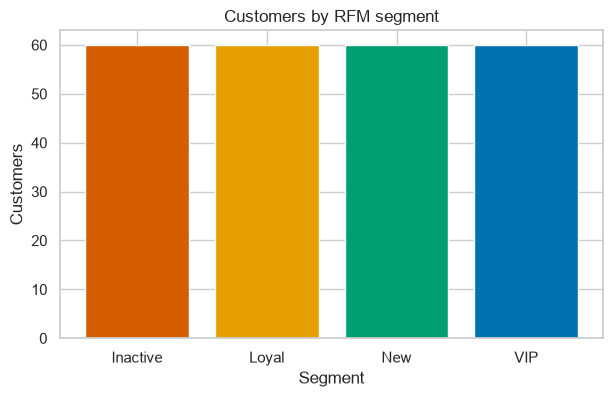

In [47]:
segment_colors = {"VIP": "#0072B2", "Loyal": "#E69F00", "New": "#009E73",
                  "Inactive": "#D55E00", "Regular": "#CC79A7"}
segment_counts = rfm["segment"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(segment_counts.index, segment_counts.values,
       color=[segment_colors[name] for name in segment_counts.index])
ax.set(title="Customers by RFM segment", xlabel="Segment", ylabel="Customers")
plt.show()

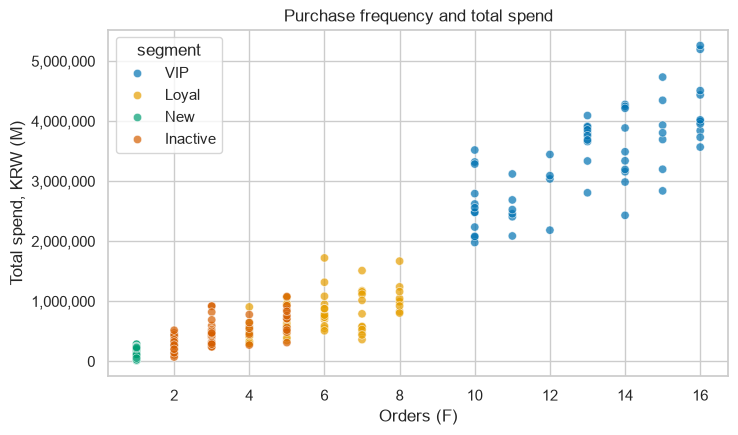

In [48]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=rfm, x="frequency", y="monetary", hue="segment",
                palette=segment_colors, alpha=0.7, ax=ax)
ax.set(title="Purchase frequency and total spend", xlabel="Orders (F)", ylabel="Total spend, KRW (M)")
ax.yaxis.set_major_formatter("{x:,.0f}")   # 축 숫자를 1,000,000처럼 표시
plt.show()

**출력 읽기:** VIP(파랑)는 오른쪽 위에 따로 떨어져 있다. 주문이 많고 금액도 크다. New(초록)는 왼쪽 아래 F = 1에 세로로 모여 있다. Loyal과 Inactive는 가운데에서 겹치는데, 이 둘을 가르는 것은 그림에 없는 R(최근성)이다.

**확인 질문:** 그룹을 점수 합계(`rfm_score`)로 나누면 어떤 문제가 생길까? 예를 들어 R=1, F=5, M=5인 고객과 R=5, F=3, M=3인 고객을 생각해 본다.
<details><summary>답 확인</summary>두 고객 모두 합계가 11점이다. 앞 고객은 예전에 많이 샀지만 오래 오지 않은 고객이고, 뒤 고객은 최근에 보통 정도로 사는 고객이다. 필요한 대응이 전혀 다르다. 합계는 이런 차이를 지우므로, 그룹은 R·F·M 각각의 조건으로 정한다.</details>

실제 데이터에서 점수 합계별로 그룹을 세어 본다.

In [49]:
display(pd.crosstab(rfm["rfm_score"], rfm["segment"], rownames=["점수 합계"], colnames=["RFM 그룹"]))

RFM 그룹,Inactive,Loyal,New,VIP
점수 합계,,,,
4,2,0,0,0
5,19,0,0,0
6,21,0,21,0
7,9,6,29,0
8,9,5,10,0
9,0,18,0,0
10,0,24,0,0
11,0,7,0,1
12,0,0,0,10


**출력 읽기:** 합계 6점 줄에는 Inactive 21명과 New 21명이 함께 있다. 오래 오지 않은 고객과 방금 첫 구매를 한 고객이 같은 점수를 받았다. 합계로 그룹을 나누면 이 둘을 구분할 수 없다.

## 8. 그룹 비교와 비즈니스 인사이트

그룹마다 고객 수, 평균 R·F·M, 매출 합계를 구하고 **비중**을 계산한다. 고객 비중의 분모는 전체 고객 수, 매출 비중의 분모는 전체 매출이다.

In [50]:
segment_summary = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    mean_recency=("recency", "mean"),
    mean_frequency=("frequency", "mean"),
    mean_monetary=("monetary", "mean"),
    revenue=("monetary", "sum"),
)
segment_summary["customer_share_pct"] = segment_summary["customers"] / segment_summary["customers"].sum() * 100
segment_summary["revenue_share_pct"] = segment_summary["revenue"] / segment_summary["revenue"].sum() * 100
summary_labels = {"customers": "고객 수", "mean_recency": "평균 R(일)", "mean_frequency": "평균 F(회)",
                  "mean_monetary": "평균 M(원)", "revenue": "매출 합계(원)",
                  "customer_share_pct": "고객 비중(%)", "revenue_share_pct": "매출 비중(%)"}
display(segment_summary.rename(columns=summary_labels))

,고객 수,평균 R(일),평균 F(회),평균 M(원),매출 합계(원),고객 비중(%),매출 비중(%)
segment,,,,,,,
Inactive,60,171.93,3.15,"459,950.00","27,597,000.00",25.00,9.68
Loyal,60,27.52,5.92,"772,971.67","46,378,300.00",25.00,16.26
New,60,4.47,1.00,"126,613.33","7,596,800.00",25.00,2.66
VIP,60,8.33,13.08,"3,393,835.00","203,630,100.00",25.00,71.40


**출력 읽기:** 고객 비중은 모두 25%로 같지만, 매출 비중은 VIP가 70%가 넘는다. 고객 넷 중 하나가 매출 대부분을 만든다. New는 고객 수는 같지만 매출 비중이 가장 작다. 아직 한 번 샀을 뿐이기 때문이다.

### 인사이트 쓰는 법 — 근거·실행·검증

미션은 README에 비즈니스 인사이트 3개 이상을, 각각 세 요소로 쓰라고 한다.

- **근거**: 인사이트를 받치는 숫자나 그래프.
- **실행**: 대상 그룹 + 실행 방법 + 기대 효과.
- **검증**: 추가로 필요한 데이터, 또는 이 주장이 틀렸다고 판단할 조건.

숫자는 표에서 가져와 문장에 넣는다. 손으로 옮겨 적으면 데이터가 바뀌었을 때 문장만 옛 숫자로 남는다. 따옴표 앞에 `f`를 붙인 **f-string**은 `{값}` 자리에 값을 끼워 넣는다. `{값:.1f}`는 소수 첫째 자리까지 표시하라는 뜻이다.

In [51]:
vip = segment_summary.loc["VIP"]
print("[VIP 인사이트]")
print(f"(근거) VIP는 고객의 {vip['customer_share_pct']:.0f}%이지만 매출의 {vip['revenue_share_pct']:.1f}%를 차지한다. "
      f"평균 주문 {vip['mean_frequency']:.1f}회, 마지막 구매 후 평균 {vip['mean_recency']:.1f}일.")
print("(실행) VIP 대상 → 전용 멤버십 혜택을 일부 고객에게 먼저 제공 → 이탈 방지와 재구매 유지 기대.")
print("(검증) 혜택을 받지 않은 VIP(대조군)와 재구매율을 비교해야 한다. 차이가 혜택 비용보다 작으면 제안을 철회한다.")

[VIP 인사이트]
(근거) VIP는 고객의 25%이지만 매출의 71.4%를 차지한다. 평균 주문 13.1회, 마지막 구매 후 평균 8.3일.
(실행) VIP 대상 → 전용 멤버십 혜택을 일부 고객에게 먼저 제공 → 이탈 방지와 재구매 유지 기대.
(검증) 혜택을 받지 않은 VIP(대조군)와 재구매율을 비교해야 한다. 차이가 혜택 비용보다 작으면 제안을 철회한다.


**출력 읽기:** 기대 효과는 아직 측정하지 않은 **가설**이다. "재구매율 10% 향상" 같은 숫자는 실험 없이 쓰지 않는다. 검증 문장이 "무엇을 보면 이 생각이 틀렸다고 판단할지"를 정해 둔다.

**확인 질문:** "New 그룹은 매출 비중이 작으니 신경 쓰지 않아도 된다"는 결론은 맞을까?
<details><summary>답 확인</summary>성급하다. New는 방금 첫 구매를 한 고객이라 매출이 작은 것이 당연하다. 중요한 질문은 "이 중 몇 명이 두 번째 구매를 하느냐"다. 확인하려면 첫 구매 이후 같은 기간 동안의 재구매 여부를 추적한 데이터가 필요하다(부록 B의 코호트 분석이 이런 추적 방법이다).</details>

## 9. DataAnalyzer — 지금까지의 단계를 클래스로 묶기

1~7장은 셀마다 변수를 만들며 진행했다. 데이터가 바뀌면 모든 셀을 같은 순서로 다시 실행해야 하고, 중간에 한 셀을 빠뜨려도 알아채기 어렵다. 미션은 이 과정을 `DataAnalyzer`라는 **클래스**로 묶으라고 한다.

| 용어 | 뜻 | 예 |
| --- | --- | --- |
| 클래스 | 데이터와 기능을 묶은 설계도 | `DataAnalyzer` |
| 객체 | 설계도로 만든 실물 하나 | `analyzer = DataAnalyzer(...)` |
| 메서드 | 객체가 가진 함수 | `analyzer.load_data()` |
| 속성(상태) | 객체가 기억하는 값 | `analyzer.df` |

메서드 안의 `self`는 "이 객체 자신"이다. `self.df = ...`라고 쓰면 그 값이 객체에 저장되어 다른 메서드에서도 쓸 수 있다. 작은 클래스로 먼저 본다.

In [52]:
class TinyAnalyzer:
    def __init__(self, values):
        self.values = pd.Series(values)   # 객체가 기억하는 데이터
        self.bounds = None                # 아직 계산하지 않음

    def find_bounds(self, threshold=1.5):
        self.bounds = iqr_bounds(self.values, threshold)
        return self.bounds

tiny = TinyAnalyzer([10, 20, 30, 40, 100])
print("계산 전 tiny.bounds:", tiny.bounds)
tiny.find_bounds()
print("계산 후 tiny.bounds:", tiny.bounds)
print("배수 3.0:", tiny.find_bounds(threshold=3.0))

계산 전 tiny.bounds: None
계산 후 tiny.bounds: (-10.0, 70.0)
배수 3.0: (-40.0, 100.0)


**출력 읽기:** `__init__`은 객체를 만들 때 자동으로 실행된다. 처음에 `bounds`는 `None`(아직 없음)이다. `find_bounds()`를 호출하면 결과가 `self.bounds`에 저장되어 객체가 기억한다. 배수 같은 기준은 인자로 받으므로, 코드를 고치지 않고 호출할 때 바꿀 수 있다.

### 실제 DataAnalyzer

프로젝트의 `src/pipeline.py`에 있는 `DataAnalyzer`는 이 노트북의 장과 이렇게 대응한다.

| 장 | 메서드 | 바꿀 수 있는 인자 |
| --- | --- | --- |
| 1~2 | `load_data()` | — |
| 3 | `handle_missing_values()` | `strategy`(median/mean), `group_col` |
| 4 | `engineer_features()` | — |
| 5 | `detect_outliers()` | `column`, `threshold` |
| 7 | `calculate_rfm()` | `recent_days`, `inactive_days`, `loyal_orders` |

순서대로 호출한다.

In [53]:
sys.path.insert(0, str(project_root))   # src 폴더를 찾을 수 있게 한다
from src.pipeline import DataAnalyzer

analyzer = DataAnalyzer(DATA / "transactions.csv")
print("load_data 전 analyzer.df:", analyzer.df)

analyzer.load_data()
analyzer.handle_missing_values(strategy="median", group_col="category")
analyzer.engineer_features()
outlier_rows = analyzer.detect_outliers("shipping_days", threshold=1.5)
analyzer_rfm = analyzer.calculate_rfm()

print("analyzer.df 모양:", analyzer.df.shape)
print("analyzer.rfm 모양:", analyzer.rfm.shape)

load_data 전 analyzer.df: None


analyzer.df 모양: (2842, 21)
analyzer.rfm 모양: (240, 8)


이제 클래스의 결과가 1~7장에서 직접 계산한 결과와 같은지 비교한다.

In [54]:
checks = {
    "3장 가격 대치": np.allclose(analyzer.df["catalog_price"], joined["catalog_price"]),
    "3장 배송 일수 대치": np.allclose(analyzer.df["shipping_days"], joined["shipping_days"]),
    "4장 이미지 평균": np.allclose(analyzer.df["image_mean"], joined["image_mean"]),
    "4장 이미지 표준편차": np.allclose(analyzer.df["image_std"], joined["image_std"]),
    "4장 상품명 단어 수": (analyzer.df["name_word_count"].to_numpy() == joined["name_word_count"].to_numpy()).all(),
    "5장 이상치 표시": (analyzer.df["shipping_days_is_outlier"] == joined["shipping_days_is_outlier"]).all(),
    "7장 R·F·M": np.allclose(analyzer_rfm[["recency", "frequency", "monetary"]], rfm[["recency", "frequency", "monetary"]]),
    "7장 1~5점": (analyzer_rfm[["r_score", "f_score", "m_score"]] == rfm[["r_score", "f_score", "m_score"]]).all().all(),
    "7장 그룹": (analyzer_rfm["segment"] == rfm["segment"]).all(),
}
display(pd.Series(checks, name="same").to_frame())

,same
3장 가격 대치,True
3장 배송 일수 대치,True
4장 이미지 평균,True
4장 이미지 표준편차,True
4장 상품명 단어 수,True
5장 이상치 표시,True
7장 R·F·M,True
7장 1~5점,True
7장 그룹,True


**출력 읽기:** 모든 항목이 True다. 클래스 안에서도 이 노트북과 같은 계산을 한다는 뜻이다.

클래스는 인자만 바꿔 다시 실행할 수 있다. 5장과 7장의 확인 질문을 클래스로 실행해 본다.

In [55]:
strict = analyzer.detect_outliers("shipping_days", threshold=3.0)
print("threshold=3.0 이상치 후보 수:", len(strict))
print(analyzer.calculate_rfm(recent_days=14)["segment"].value_counts().to_dict())

threshold=3.0 이상치 후보 수: 15
{'Loyal': 66, 'New': 60, 'Inactive': 60, 'VIP': 54}


**출력 읽기:** 7장에서 `assign_segments(rfm, recent_days=14)`로 본 결과와 같다.

`src/pipeline.py`를 열어 보면 이 노트북에 없던 코드가 더 있다. 대부분 **입력 검사**다. 필요한 열이 있는지, ID가 중복되지 않는지, 금액 = 단가 × 수량인지 등을 확인하고, 문제가 있으면 틀린 숫자를 내는 대신 오류로 멈춘다. 처음 읽을 때는 검사 부분을 건너뛰고 `merge`, `groupby`, `mean(axis=...)`처럼 이 노트북에서 본 줄을 찾아 읽으면 된다.

## 정리

| 장 | 한 일 | 핵심 도구 |
| --- | --- | --- |
| 1 | 행의 단위(상품 한 줄) 확인, 구조 파악 | `shape`, `nunique`, `info`, `describe` |
| 2 | 거래 표와 상품 표 연결 | `merge(validate="many_to_one")` |
| 3 | 카테고리 중앙값으로 결측치 채우기 | `groupby().transform("median")`, `fillna`, `map` |
| 4 | 이미지 → 평균·표준편차, 상품명 → 길이 | `mean(axis=(1, 2, 3))`, `str.len` |
| 5 | IQR 이상치 후보 찾기, 처리 비교 | `quantile`, `clip`, 박스플롯 |
| 6 | 요약 통계, 상관계수, 월별 추세 | `describe`, `corr`, 히스토그램·히트맵·라인차트 |
| 7 | 고객별 R·F·M, 점수, 그룹 | `groupby().agg`, `rank(pct=True)`, `np.select` |
| 8 | 그룹 비교, 근거·실행·검증 | 비중 계산, f-string |
| 9 | 단계를 클래스로 묶기 | `DataAnalyzer`, `self` |

미션의 과제 목표를 자기 말로 설명해 본다.

1. 반복문 없이 이미지 80장의 평균을 구하는 방법과, `axis`가 무엇을 정하는지.
2. 768개의 픽셀이 평균·표준편차 두 숫자가 되는 과정과, 그 두 숫자가 알려주지 못하는 것.
3. IQR 경계를 계산하는 순서와, 후보를 바로 지우지 않는 이유.
4. 거래 행이 고객 한 행으로 바뀌는 과정, F를 행 수가 아닌 주문 수로 세는 이유, 그룹 기준을 바꾸면 결과가 달라지는 이유.
5. 같은 계산을 클래스로 묶었을 때 얻는 것(재실행, 인자로 기준 바꾸기, 입력 검사).

# 부록 — 보너스 과제

본편의 `joined`, `rfm`, `images`를 그대로 쓴다. 각 부록은 먼저 이미지 한 장이나 한 칸을 직접 계산하고, 프로젝트의 `src/bonus.py` 함수 결과와 비교한다.

## A. 이미지 고급 피처 — 히스토그램·엣지·엔트로피

평균·표준편차는 이미지를 두 숫자로 줄인다. 조금 더 자세히 요약하는 방법 세 가지를 만든다.

**1단계: 흑백으로 바꾸기.** 색 세 개를 밝기 하나로 합친다. 사람 눈은 초록을 더 밝게 느끼므로 가중치를 다르게 준다: 밝기 = 0.2126 × R + 0.7152 × G + 0.0722 × B. `@`는 마지막 축(RGB 3개)과 가중치 3개를 곱해 더하는 연산이다.

In [56]:
luminance_weights = np.array([0.2126, 0.7152, 0.0722])
gray = images @ luminance_weights
print("컬러:", images.shape, "→ 흑백:", gray.shape)
print("0번 이미지 왼쪽 위 픽셀:", images[0, 0, 0], "→", gray[0, 0, 0])

컬러:

 (80, 16, 16, 3) → 흑백: (80, 16, 16)
0번 이미지 왼쪽 위 픽셀: [59  0 48] → 16.009


**2단계: 밝기 히스토그램.** 0~255를 폭 32인 구간 8개로 나누고, 각 구간에 픽셀이 몇 %인지 센다. 평균이 같아도 "중간 밝기만 있는 이미지"와 "아주 어두운 곳과 아주 밝은 곳이 섞인 이미지"를 구분할 수 있다.

**3단계: 엣지(이웃 차이).** 바로 옆 픽셀과 밝기가 얼마나 다른지의 평균이다. `np.diff`는 이웃끼리 뺀다. [10, 10, 50, 50]이면 차이는 [0, 40, 0]이다. 경계·무늬가 많을수록 커진다.

**4단계: 엔트로피.** 히스토그램이 얼마나 고르게 퍼졌는지다. 모든 픽셀이 한 구간이면 0, 8구간에 똑같이 퍼지면 최댓값 3(bit)이다. 계산식은 −Σ p × log₂ p (p = 구간 비율)다.

0번 이미지로 직접 계산한다.

In [57]:
print("np.diff([10, 10, 50, 50]) =", np.diff([10, 10, 50, 50]))

one = gray[0]
counts, edges = np.histogram(one, bins=8, range=(0, 256))
hand_hist = counts / one.size

vertical_diff = np.abs(np.diff(one, axis=0))     # 위아래 이웃 차이: (15, 16)
horizontal_diff = np.abs(np.diff(one, axis=1))   # 좌우 이웃 차이: (16, 15)
hand_edge = (vertical_diff.sum() + horizontal_diff.sum()) / (vertical_diff.size + horizontal_diff.size)

nonzero = hand_hist[hand_hist > 0]
hand_entropy = -(nonzero * np.log2(nonzero)).sum()

print("구간 경계:", edges)
print("히스토그램(비율):", hand_hist.round(3))
print("엣지:", round(hand_edge, 3), " 엔트로피:", round(hand_entropy, 3))

np.diff([10, 10, 50, 50]) = [ 0 40  0]
구간 경계: [  0.  32.  64.  96. 128. 160. 192. 224. 256.]
히스토그램(비율): [0.199 0.484 0.297 0.02  0.    0.    0.    0.   ]
엣지: 18.97  엔트로피: 1.601


**출력 읽기:** 히스토그램 8개의 합은 1(100%)이다. 0으로 나누거나 log(0)을 계산하지 않도록 비율이 0인 구간은 엔트로피에서 뺀다.

`src/bonus.py`의 `image_features`는 같은 계산을 80장에 반복문 없이 한다. 0번 행이 직접 계산과 같은지 본다.

In [58]:
from src.bonus import image_features

image_extra = image_features(images)
print("결과 모양:", image_extra.shape)
display(image_extra.head(3).round(3))
print("0번 이미지 직접 계산과 같음:",
      np.allclose(image_extra.iloc[0, :8], hand_hist),
      np.isclose(image_extra.loc[0, "image_edge_mean"], hand_edge),
      np.isclose(image_extra.loc[0, "image_entropy"], hand_entropy))

결과 모양: (80, 10)


,image_hist_0,image_hist_1,image_hist_2,image_hist_3,image_hist_4,image_hist_5,image_hist_6,image_hist_7,image_edge_mean,image_entropy
0,0.20,0.48,0.30,0.02,0.00,0.00,0.00,0.00,18.97,1.60
1,0.00,0.00,0.01,0.13,0.48,0.34,0.04,0.00,22.95,1.66
2,0.00,0.00,0.00,0.10,0.38,0.42,0.10,0.00,22.63,1.73


0번 이미지 직접 계산과 같음: True True True


**출력 읽기:** 이미지마다 피처 10개(히스토그램 8 + 엣지 + 엔트로피)가 생겼다. 4장처럼 `image_index`로 거래 행에 붙일 수 있다. 이 값들도 밝기 분포와 질감의 요약일 뿐, 상품이 무엇인지는 모른다.

## B. 가입 월별 코호트 — 시간이 지나도 다시 오나

**코호트**는 같은 시기에 시작한 사람들의 묶음이다. 가입한 달이 같은 고객끼리 묶고, 가입 후 0개월, 1개월, 2개월… 에 구매한 고객의 비율(**활동률**)을 본다.

- 분모: 그 달에 가입한 고객 수(한 번도 사지 않은 고객 포함).
- 분자: 가입 후 n개월째 달에 한 번이라도 산 고객 수.

가입일은 `customers.csv`에 있다.

In [59]:
customers = pd.read_csv(DATA / "customers.csv", dtype={"customer_id": "string"}, parse_dates=["signup_date"])
customers["cohort"] = customers["signup_date"].dt.to_period("M")
display(customers.head(3))
display(customers["cohort"].value_counts().sort_index().to_frame("signups").T)

,customer_id,signup_date,cohort
0,C000,2026-02-01,2026-02
1,C001,2026-04-29,2026-04
2,C002,2026-04-19,2026-04


cohort,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
signups,2,8,20,26,19,19,36,28,32,24,22,4


2026년 3월 가입 코호트의 1개월 후(4월) 활동률을 직접 계산한다. `isin`은 "목록 안에 있는가"를 검사한다.

In [60]:
cohort_month = pd.Period("2026-03", freq="M")
members = customers.loc[customers["cohort"] == cohort_month, "customer_id"]
target_month = cohort_month + 1

bought_in_target = joined[joined["customer_id"].isin(members)
                          & (joined["order_date"].dt.to_period("M") == target_month)]
active_customers = bought_in_target["customer_id"].nunique()

print("가입 고객:", len(members), " 다음 달에 산 고객:", active_customers)
print("활동률:", active_customers / len(members))

가입 고객: 19  다음 달에 산 고객: 3
활동률: 0.15789473684210525


`src/bonus.py`의 `signup_cohorts`는 모든 칸을 같은 방식으로 계산한다. 단, 관측 기간이 한 달을 다 채우지 못한 칸(예: 10월은 9일까지만 있다)은 계산하지 않고 비워 둔다. 빈 칸을 0%로 읽으면 "아무도 안 왔다"로 오해하기 때문이다.

직접 계산과 같음:

 True


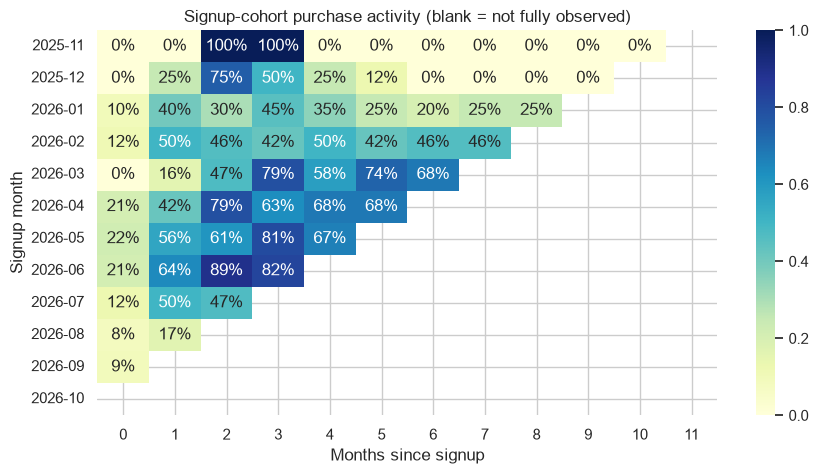

In [61]:
from src.bonus import signup_cohorts

cohort_sizes, cohort_counts, cohort_rates = signup_cohorts(joined, customers)
print("직접 계산과 같음:", np.isclose(cohort_rates.loc[cohort_month, 1], active_customers / len(members)))

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(cohort_rates, mask=cohort_rates.isna(), vmin=0, vmax=1, cmap="YlGnBu",
            annot=True, fmt=".0%", ax=ax)
ax.set(title="Signup-cohort purchase activity (blank = not fully observed)",
       xlabel="Months since signup", ylabel="Signup month")
plt.show()

**출력 읽기:** 한 행이 한 코호트, 오른쪽으로 갈수록 가입 후 시간이 지난 것이다. 오른쪽 아래가 비어 있는 것은 아직 그만큼 시간이 지나지 않았기 때문이다. 이 데이터의 가입일은 첫 구매일에서 0~90일을 빼서 만든 값이라, 실제 고객의 유지율로 읽지 않는다.

## C. 인터랙티브 시각화 — Plotly

7장의 산점도를 마우스로 조작할 수 있게 만든다. 이 보너스에 한해 Plotly 사용이 허용된다.

- 점에 마우스를 올리면 고객 ID와 R·F·M 점수가 나온다.
- 범례의 그룹 이름을 누르면 그 그룹을 숨기거나 보인다.
- 드래그하면 확대하고, 더블클릭하면 원래대로 돌아간다.

그림을 그리는 데 필요한 Plotly 프로그램은 인터넷(CDN)에서 불러오므로, 인터넷이 연결되어 있어야 차트가 보인다.

In [62]:
from IPython.display import HTML
from src.bonus import interactive_rfm

figure = interactive_rfm(analyzer.calculate_rfm())
HTML(figure.to_html(include_plotlyjs="cdn", full_html=False))

**출력 읽기:** 정적인 산점도에서는 겹친 점의 고객을 알 수 없었지만, 여기서는 점마다 정보를 확인할 수 있다. 보여주는 방식만 바뀌었고 RFM 계산은 같다.